# 京都大学 2026 理系 第3問 — Julia + Wolfram Engine で解く

## 問題

$n$ は正の整数とする。整数係数の多項式 $(x+1)^{2^{n+1}} - (x^2+1)^{2^n}$ のすべての係数が $2^m$ で割り切れるような正の整数 $m$ のうち，最大のものは $n+1$ であることを示せ。ただし，$(x+1)^{2^{n+1}}$ は $x+1$ の $2^{n+1}$ 乗を表す。$(x^2+1)^{2^n}$ は $x^2+1$ の $2^n$ 乗を表す。$2^m$ は $2$ の $m$ 乗を表す。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl");     # MathLink の読み込みと，共通の関数（表示・変換）

## 1. 展開して係数を見る

$n$ を与えると多項式 $(x+1)^{2^{n+1}} - (x^2+1)^{2^n}$ を Wolfram の式として作る関数 `poly(n)` を用意し，`Expand` で展開します。

In [2]:
poly(n) = wparse("(x + 1)^(2^($n + 1)) - (x^2 + 1)^(2^$n)")      # Wolfram の式（未評価）
expand(n) = weval(W"Expand"(poly(n)))                             # 展開した式

for n in 1:3
    showtex("n = $n:\\quad " * tex(W"HoldForm"(poly(n))) * " = " * tex(expand(n)))
end

引く前の 2 つの多項式はどちらも $2^{n+1}$ 次ですが，最高次の項 $x^{2^{n+1}}$ と定数項 $1$ は打ち消し合って消え，$2^{n+1}-1$ 次式になっています。

### 係数を Julia の配列にする

`CoefficientList` で係数を低い次数から順に取り出し，Julia の配列にします（`c[1]` が定数項，`c[k+1]` が $x^k$ の係数）。

In [3]:
coeffs(n) = to_value(weval(W"CoefficientList"(expand(n), W"x")))

for n in 1:4
    println("n = $(n)（", 2^(n + 1) - 1, " 次式）")
    println("  ", coeffs(n))
end

n = 1（3 次式）
  [0, 4, 4, 4]
n = 2（7 次式）
  [0, 8, 24, 56, 64, 56, 24, 8]
n = 3（15 次式）
  [0, 16, 112, 560, 1792, 4368, 7952, 11440, 12800, 11440, 7952, 4368, 1792, 560, 112, 16]
n = 4（31 次式）
  [0, 32, 480, 4960, 35840, 201376, 905632, 3365856, 10516480, 28048800, 64507872, 129024480, 225784832, 347373600, 471424160, 565722720, 601067520, 565722720, 471424160, 347373600, 225784832, 129024480, 64507872, 28048800, 10516480, 3365856, 905632, 201376, 35840, 4960, 480, 32]


### 気づくこと

- 係数は左右対称に並んでいます（$x^k$ と $x^{2^{n+1}-k}$ の係数が等しい）。
- $n = 1$ では係数はすべて $4 = 2^2$，$n = 2$ では $8 = 2^3$ の倍数に見えます。

## 2. 因数分解してみる

`Factor` で整数係数の範囲で因数分解します。

In [4]:
for n in 1:4
    showtex("n = $n:\\quad " * tex(weval(W"Factor"(poly(n)))))
end

### 気づくこと

- 先頭の数は $4,\ 8,\ 16,\ 32$ で，ちょうど $2^{n+1}$ です。
- $n$ が 1 増えるごとに，それまでの因数はそのまま残り，新しい因数が 1 つ加わります。
- 加わる因数はどれも**定数項と最高次の係数が $1$** です。

### なぜそうなるか：2 乗の差

$A = (x+1)^{2^n}$，$B = (x^2+1)^{2^{n-1}}$ とおくと，$(x+1)^{2^{n+1}} = A^2$，$(x^2+1)^{2^n} = B^2$ なので，

$$(x+1)^{2^{n+1}} - (x^2+1)^{2^n} = A^2 - B^2 = (A - B)(A + B)$$

$A - B$ は $n$ を 1 つ小さくした多項式そのものです。つまり，$n$ のときの多項式を $F_n(x)$ と書くと

$$F_n(x) = F_{n-1}(x)\cdot\left\{(x+1)^{2^n} + (x^2+1)^{2^{n-1}}\right\}$$

新しく掛かる $A + B$ のほうを因数分解してみます。

In [5]:
plus(n) = wparse("(x + 1)^(2^$n) + (x^2 + 1)^(2^($n - 1))")      # A + B

for n in 1:4
    showtex("n = $n:\\quad " * tex(W"HoldForm"(plus(n))) * " = " * tex(weval(W"Factor"(plus(n)))))
end

どれも「$2 \times$（定数項が $1$ の多項式）」の形で，上の因数分解で新しく加わった因数と一致しています。

出発点は $n = 0$ にあたる $F_0(x) = (x+1)^2 - (x^2+1)$ です。

In [6]:
showtex("F_0(x) = " * tex(weval(W"Factor"(poly(0)))))

まとめると，$A + B = 2\,G_n(x)$ とおけば

$$F_n(x) = F_0(x)\cdot 2G_1(x)\cdot 2G_2(x)\cdots 2G_n(x) = 2^{n+1}\,x\,G_1(x)\,G_2(x)\cdots G_n(x)$$

という形になっています。$F_n(x) = F_{n-1}(x) \cdot 2G_n(x)$ が成り立つことを，展開して確かめておきます。

In [7]:
for n in 1:5
    println("n = $(n)： F_n = F_(n-1) × (A + B) は ", weval(W"Expand"(W"Subtract"(poly(n), W"Times"(poly(n - 1), plus(n))))) == 0)
end

n = 1： F_n = F_(n-1) × (A + B) は true
n = 2： F_n = F_(n-1) × (A + B) は true
n = 3： F_n = F_(n-1) × (A + B) は true
n = 4： F_n = F_(n-1) × (A + B) は true
n = 5： F_n = F_(n-1) × (A + B) は true


## 3. 二項定理で係数を計算する

$N = 2^n$ とおくと，二項定理より

$$(x+1)^{2N} = \sum_{k=0}^{2N} \binom{2N}{k} x^k,\qquad (x^2+1)^{N} = \sum_{j=0}^{N} \binom{N}{j} x^{2j}$$

2 つ目は偶数次の項しかありません。したがって，$x^k$ の係数 $c_k$ は

$$c_k = \begin{cases} \dbinom{2^{n+1}}{k} & (k\ \text{が奇数}) \\[2ex] \dbinom{2^{n+1}}{k} - \dbinom{2^n}{k/2} & (k\ \text{が偶数}) \end{cases}$$

これを Julia の関数にして，1 節で Wolfram に展開させた係数と比べます（大きな数になるので `big` を使います）。

In [8]:
# 二項定理による x^k の係数
function c(n, k)
    N = big(2)^n
    iseven(k) ? binomial(2N, k) - binomial(N, k ÷ 2) : binomial(2N, k)
end

cbinom(n) = [c(n, k) for k in 0:2^(n+1)-1]      # 定数項から 2^(n+1)-1 次まで

@show cbinom(1) cbinom(2) cbinom(3)

for n in 1:6
    println("n = $(n)： Wolfram の展開と一致 → ", cbinom(n) == coeffs(n))
end

cbinom(1) = BigInt[0, 4, 4, 4]
cbinom(2) = BigInt[0, 8, 24, 56, 64, 56, 24, 8]
cbinom(3) = BigInt[0, 16, 112, 560, 1792, 4368, 7952, 11440, 12800, 11440, 7952, 4368, 1792, 560, 112, 16]
n = 1： Wolfram の展開と一致 → true
n = 2： Wolfram の展開と一致 → true
n = 3： Wolfram の展開と一致 → true
n = 4： Wolfram の展開と一致 → true
n = 5： Wolfram の展開と一致 → true
n = 6： Wolfram の展開と一致 → true


### 係数が $2$ で何回割り切れるか

各係数が $2$ でちょうど何回割り切れるか（$2$ の指数）を調べます。Julia では `trailing_zeros` で求められます。$k$ が奇数のときと偶数のときに分けて並べます（$c_0 = 0$ は除く）。

In [9]:
v2(m) = trailing_zeros(m)      # m が 2 でちょうど何回割り切れるか

for n in 1:4
    ks = 1:2^(n+1)-1
    println("n = $(n)（n + 1 = $(n + 1)）")
    println("  k が奇数： ", [v2(c(n, k)) for k in ks if isodd(k)])
    println("  k が偶数： ", [v2(c(n, k)) for k in ks if iseven(k)])
    println("  最小値 = ", minimum(v2(c(n, k)) for k in ks))
end

n = 1（n + 1 = 2）
  k が奇数： [2, 2]
  k が偶数： [2]
  最小値 = 2
n = 2（n + 1 = 3）
  k が奇数： [3, 3, 3, 3]
  k が偶数： [3, 6, 3]
  最小値 = 3
n = 3（n + 1 = 4）
  k が奇数： [4, 4, 4, 4, 4, 4, 4, 4]
  k が偶数： [4, 8, 4, 9, 4, 8, 4]
  最小値 = 4
n = 4（n + 1 = 5）
  k が奇数： [5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
  k が偶数： [5, 10, 5, 11, 5, 10, 5, 12, 5, 10, 5, 11, 5, 10, 5]
  最小値 = 5


もう少し大きい $n$ でも，最小値が $n + 1$ になっていることを確かめます。

In [10]:
for n in 1:10
    ks = 1:2^(n+1)-1
    println("n = ", lpad(n, 2), "： 2 の指数の最小値 = ", lpad(minimum(v2(c(n, k)) for k in ks), 2),
            "   k が奇数のときすべて n+1 か → ", all(v2(c(n, k)) == n + 1 for k in ks if isodd(k)))
end

n =  1： 2 の指数の最小値 =  2   k が奇数のときすべて n+1 か → true
n =  2： 2 の指数の最小値 =  3   k が奇数のときすべて n+1 か → true
n =  3： 2 の指数の最小値 =  4   k が奇数のときすべて n+1 か → true
n =  4： 2 の指数の最小値 =  5   k が奇数のときすべて n+1 か → true
n =  5： 2 の指数の最小値 =  6   k が奇数のときすべて n+1 か → true
n =  6： 2 の指数の最小値 =  7   k が奇数のときすべて n+1 か → true
n =  7： 2 の指数の最小値 =  8   k が奇数のときすべて n+1 か → true
n =  8： 2 の指数の最小値 =  9   k が奇数のときすべて n+1 か → true
n =  9： 2 の指数の最小値 = 10   k が奇数のときすべて n+1 か → true
n = 10： 2 の指数の最小値 = 11   k が奇数のときすべて n+1 か → true


### グラフで見る（$n = 5$）

横軸を $k$，縦軸を $c_k$ の $2$ の指数として点を打ちます。

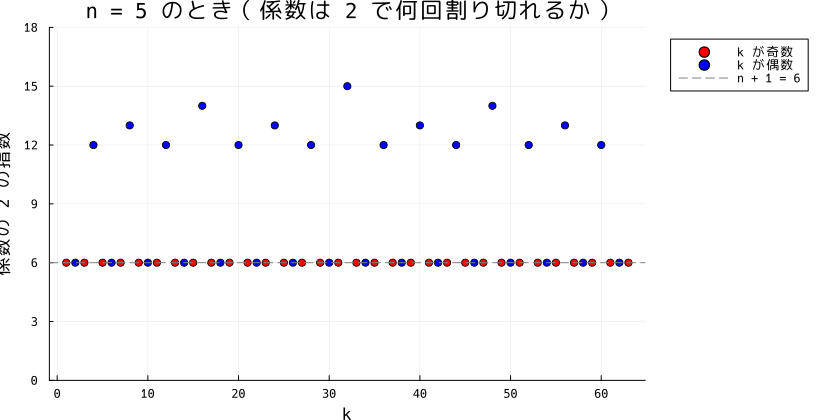

In [11]:
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

n = 5
ko, ke = 1:2:2^(n+1)-1, 2:2:2^(n+1)-2
scatter(ko, [v2(c(n, k)) for k in ko]; color=:red, label="k が奇数", xlabel="k", ylabel="係数の 2 の指数",
        title="n = 5 のとき（係数は 2 で何回割り切れるか）", legend=:outertopright, size=(820, 420), ylims=(0, 18))
scatter!(ke, [v2(c(n, k)) for k in ke]; color=:blue, label="k が偶数")
hline!([n + 1]; color=:gray, ls=:dash, label="n + 1 = 6")

### 分かったこと

- **$k$ が奇数のとき**：$c_k = \dbinom{2^{n+1}}{k}$ の $2$ の指数は，いつもちょうど $n + 1$。
  - とくに $k = 1$ のとき $c_1 = \dbinom{2^{n+1}}{1} = 2^{n+1}$ なので，$m$ は $n + 1$ より大きくできません（$m \leqq n + 1$）。
  - 一般の奇数 $k$ では $k\dbinom{2^{n+1}}{k} = 2^{n+1}\dbinom{2^{n+1}-1}{k-1}$ から，$2^{n+1}$ の倍数であることが分かります。
- **$k$ が偶数のとき**：$c_k = \dbinom{2^{n+1}}{k} - \dbinom{2^n}{k/2}$ の $2$ の指数は $n + 1$ 以上。
  - こちらは 2 つの二項係数の**差**なので，二項定理だけで $2^{n+1}$ の倍数と示すのは手間がかかります。2 節の因数分解（$F_n = F_{n-1} \times 2G_n$）を使った帰納法のほうが楽そうです。

## 4. 因数分解と帰納法で示す

$n \geqq 0$ に対して

$$F_n(x) = (x+1)^{2^{n+1}} - (x^2+1)^{2^n},\qquad S_n(x) = (x+1)^{2^n} + (x^2+1)^{2^{n-1}}\quad(n \geqq 1)$$

とおきます。2 節で見たように，2 乗の差の因数分解から

$$F_n(x) = F_{n-1}(x)\,S_n(x) \qquad\cdots\ (1)$$

です。また，$F_{n-1}$ の定義から $(x+1)^{2^n} = F_{n-1}(x) + (x^2+1)^{2^{n-1}}$ なので，

$$S_n(x) = F_{n-1}(x) + 2\,(x^2+1)^{2^{n-1}} \qquad\cdots\ (2)$$

と書けます。**(2) が鍵**で，「$F_{n-1}$ の係数が偶数なら $S_n$ の係数も偶数」と分かります。

まず (1)，(2) を Wolfram で確かめます。

In [12]:
sq(n) = wparse("(x^2 + 1)^(2^($n - 1))")      # (x² + 1)^(2^(n-1))

for n in 1:6
    eq1 = weval(W"Expand"(W"Subtract"(poly(n), W"Times"(poly(n - 1), plus(n))))) == 0
    eq2 = weval(W"Expand"(W"Subtract"(plus(n), W"Plus"(poly(n - 1), W"Times"(2, sq(n)))))) == 0
    println("n = $(n)： (1) は $(eq1)，(2) は $eq2")
end

n = 1： (1) は true，(2) は true
n = 2： (1) は true，(2) は true
n = 3： (1) は true，(2) は true
n = 4： (1) は true，(2) は true
n = 5： (1) は true，(2) は true
n = 6： (1) は true，(2) は true


### 示すこと

> **命題 $(\ast)$**：$n \geqq 0$ に対して，$F_n(x) = 2^{n+1}\,x\,H_n(x)$ と表せる。ただし $H_n(x)$ は整数係数の多項式で，定数項は $1$。

これが言えれば，

- $F_n$ のすべての係数は $2^{n+1}$ で割り切れる。
- $x$ の係数は $2^{n+1} \times (H_n\text{ の定数項}) = 2^{n+1}$ で，$2^{n+2}$ では割り切れない。

となり，最大の $m$ は $n + 1$ です。

### 実験：$H_n$ と $G_n = \dfrac{S_n}{2}$ の係数

$H_n(x) = \dfrac{F_n(x)}{2^{n+1}x}$ と $G_n(x) = \dfrac{S_n(x)}{2}$ の係数を Julia の配列にして，整数かどうか，定数項が $1$ かどうかを見ます。

In [13]:
Hcoef(n) = to_value(weval(W"CoefficientList"(W"Cancel"(W"Divide"(poly(n), wparse("2^($n + 1) x"))), W"x")))      # H_n の係数
Gcoef(n) = to_value(weval(W"CoefficientList"(W"Expand"(W"Divide"(plus(n), 2)), W"x")))                          # G_n の係数

allint(v) = all(a -> a isa Integer, v)      # すべて整数か

@show Hcoef(0) Hcoef(1) Hcoef(2)
@show Gcoef(1) Gcoef(2) Gcoef(3)
println()
for n in 1:7
    h, g = Hcoef(n), Gcoef(n)
    println("n = $(n)： H_n は整数係数 $(allint(h))，定数項 $(h[1])　／　G_n は整数係数 $(allint(g))，定数項 $(g[1])")
end

Hcoef(0) = [1]
Hcoef(1) = [1, 1, 1]
Hcoef(2) = [1, 3, 7, 8, 7, 3, 1]
Gcoef(1) = [1, 1, 1]
Gcoef(2) = [1, 2, 4, 2, 1]
Gcoef(3) = [1, 4, 16, 28, 38, 28, 16, 4, 1]

n = 1： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 2： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 3： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 4： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 5： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 6： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1
n = 7： H_n は整数係数 true，定数項 1　／　G_n は整数係数 true，定数項 1


### 証明

**[1] $n = 0$ のとき**

$F_0(x) = (x+1)^2 - (x^2+1) = 2x = 2^1 \cdot x \cdot 1$ なので，$H_0(x) = 1$ として $(\ast)$ は成り立つ。

**[2] $n - 1$ のとき成り立つと仮定する（$n \geqq 1$）**

仮定より $F_{n-1}(x) = 2^n\,x\,H_{n-1}(x)$（$H_{n-1}$ は整数係数，定数項 $1$）。これを (2) に代入すると

$$S_n(x) = 2^n\,x\,H_{n-1}(x) + 2\,(x^2+1)^{2^{n-1}} = 2\left\{2^{n-1}\,x\,H_{n-1}(x) + (x^2+1)^{2^{n-1}}\right\}$$

$n \geqq 1$ より $2^{n-1}$ は整数だから，

$$G_n(x) = 2^{n-1}\,x\,H_{n-1}(x) + (x^2+1)^{2^{n-1}}$$

は整数係数の多項式で，$S_n(x) = 2\,G_n(x)$。$G_n$ の定数項は，第 1 項が $x$ を含むので $0 + 1 = 1$。

(1) より

$$F_n(x) = F_{n-1}(x)\,S_n(x) = 2^n\,x\,H_{n-1}(x) \cdot 2\,G_n(x) = 2^{n+1}\,x\,H_{n-1}(x)\,G_n(x)$$

$H_n(x) = H_{n-1}(x)\,G_n(x)$ とおくと，整数係数の多項式どうしの積なので整数係数で，定数項は $1 \times 1 = 1$。よって $n$ のときも $(\ast)$ は成り立つ。

**[1]，[2] より**，すべての $n \geqq 0$ で $(\ast)$ が成り立つ。

### 結論

正の整数 $n$ に対して $F_n(x) = 2^{n+1}\,x\,H_n(x)$（$H_n$ は整数係数，定数項 $1$）なので，

- $F_n(x)$ のすべての係数は $2^{n+1}$ で割り切れる。よって $m = n + 1$ は条件を満たす。
- $x$ の係数は $2^{n+1}$ であり，$m \geqq n + 2$ のとき $2^m$ では割り切れない。

したがって，条件を満たす正の整数 $m$ のうち最大のものは $n + 1$ である。（証明終）

### 証明で使った式を確かめる

証明の中で出てきた $G_n(x) = 2^{n-1}\,x\,H_{n-1}(x) + (x^2+1)^{2^{n-1}}$ と $H_n(x) = H_{n-1}(x)\,G_n(x)$ を，Wolfram で確かめます。

In [14]:
Hw(n) = weval(W"Cancel"(W"Divide"(poly(n), wparse("2^($n + 1) x"))))      # H_n（Wolfram の式）
Gw(n) = weval(W"Expand"(W"Divide"(plus(n), 2)))                            # G_n（Wolfram の式）

for n in 1:6
    eqG = weval(W"Expand"(W"Subtract"(Gw(n), W"Plus"(W"Times"(wparse("2^($n - 1) x"), Hw(n - 1)), sq(n))))) == 0
    eqH = weval(W"Expand"(W"Subtract"(Hw(n), W"Times"(Hw(n - 1), Gw(n))))) == 0
    println("n = $(n)： G_n の式は $(eqG)，H_n = H_(n-1) G_n は $eqH")
end

n = 1： G_n の式は true，H_n = H_(n-1) G_n は true
n = 2： G_n の式は true，H_n = H_(n-1) G_n は true
n = 3： G_n の式は true，H_n = H_(n-1) G_n は true
n = 4： G_n の式は true，H_n = H_(n-1) G_n は true
n = 5： G_n の式は true，H_n = H_(n-1) G_n は true
n = 6： G_n の式は true，H_n = H_(n-1) G_n は true


### 3 節（二項定理）とのつながり

- $x$ の係数が $2^{n+1}$ であることは，二項定理の $c_1 = \dbinom{2^{n+1}}{1} = 2^{n+1}$ と同じ事実です。
- 3 節で手間がかかりそうだった「偶数次の係数 $\dbinom{2^{n+1}}{k} - \dbinom{2^n}{k/2}$ が $2^{n+1}$ の倍数」は，この帰納法でまとめて示せたことになります。

## 5. 帰納法の計算部分を，$n$ を文字のまま Wolfram で確かめる

4 節の検算は $n = 1, 2, \dots$ と具体的な数を入れたものでした。ここでは **$n$ を文字のまま**，さらに $F_n,\ S_n,\ H_n$ を**中身を定義しない抽象的な関数**のままにして，帰納法の中の式変形を Wolfram に実行させます。

Wolfram では，定義していない関数 `F[n, x]` はそのまま記号として残り，置き換え規則 `/.` で「帰納法の仮定」を代入できます。

| 記号 | 意味 |
|:--|:--|
| `F[n, x]` | $F_n(x)$ |
| `S[n, x]` | $S_n(x)$ |
| `H[n, x]` | $H_n(x)$ |
| `B[n, x]` | $(x^2+1)^{2^{n-1}}$ |

### 準備：(1)，(2) を $n$ を文字のまま確かめる

まず，具体的な定義から (1) $F_n = F_{n-1}S_n$ と (2) $S_n = F_{n-1} + 2(x^2+1)^{2^{n-1}}$ が成り立つことを，$n$ に数を入れずに確かめます（どちらも $0$ になれば成り立つ）。

In [ ]:
Fd(m) = "((x + 1)^(2^(($m) + 1)) - (x^2 + 1)^(2^($m)))"      # F_m の定義（m は文字式でもよい）
Sd = "((x + 1)^(2^n) + (x^2 + 1)^(2^(n - 1)))"                 # S_n の定義
Bd = "(x^2 + 1)^(2^(n - 1))"                                   # B_n の定義

c1 = weval(wparse("Simplify[Expand[$(Fd("n")) - $(Fd("n - 1")) $Sd]]"))
c2 = weval(wparse("Simplify[$Sd - ($(Fd("n - 1")) + 2 $Bd)]"))
showtex("F_n - F_{n-1}S_n = " * tex(c1) * ",\\qquad S_n - \\left\\{F_{n-1} + 2\\,(x^2+1)^{2^{n-1}}\\right\\} = " * tex(c2))

### 帰納法のステップを抽象的な関数のまま計算する

(1)，(2) の右辺と，帰納法の仮定 $F_{n-1}(x) = 2^n\,x\,H_{n-1}(x)$ を，Wolfram の式と置き換え規則として書きます。

In [ ]:
rel1 = "F[n - 1, x] S[n, x]"                      # (1) の右辺：F_n = F_(n-1) S_n
rel2 = "F[n - 1, x] + 2 B[n, x]"                  # (2) の右辺：S_n = F_(n-1) + 2 B_n
hyp  = "F[n - 1, x] -> 2^n x H[n - 1, x]"         # 帰納法の仮定（置き換え規則）

Snw = weval(wparse("($rel2) /. $hyp"))                        # (2) に仮定を代入
Gnw = weval(wparse("Expand[(($rel2) /. $hyp)/2]"))            # 2 で割る
showtex("S_n(x) = " * tex(Snw))
showtex("G_n(x) = \\frac{S_n(x)}{2} = " * tex(Gnw))

$S_n$ が $2 \times$（$2^{n-1}\,x\,H_{n-1} + B_n$）の形になっていれば，証明の中の $G_n$ の式と同じです。

次に (1) に (2) と仮定を代入して $F_n$ を計算し，$2^{n+1}\,x\,H_{n-1}(x)\,G_n(x)$ との差が $0$ になることを確かめます。

In [ ]:
Fnw = weval(wparse("Expand[(($rel1) /. S[n, x] -> ($rel2)) /. $hyp]"))      # (1) に (2) と仮定を代入して展開
showtex("F_n(x) = " * tex(Fnw))

diff = weval(W"Simplify"(W"Subtract"(Fnw, W"Times"(wparse("2^(n + 1) x H[n - 1, x]"), Gnw))))
showtex("F_n(x) - 2^{n+1}\\,x\\,H_{n-1}(x)\\,G_n(x) = " * tex(diff))

### $G_n$ の定数項

$G_n(x)$ に $x = 0$ を代入します。抽象的な関数のままでは $B_n(0)$ が残るので，そこだけ具体的な定義 $(x^2+1)^{2^{n-1}}$ で $x = 0$ としたものを計算します。

In [ ]:
g0 = weval(W"ReplaceAll"(Gnw, W`x -> 0`))
b0 = weval(wparse("$Bd /. x -> 0"))
showtex("G_n(0) = " * tex(g0) * ",\\qquad B_n(0) = " * tex(b0))

### ここまでで確かめられたこと・確かめられないこと

**Wolfram が確かめてくれること**（$n$ は文字のまま）

- (1)，(2) の等式
- 仮定 $F_{n-1} = 2^n\,x\,H_{n-1}$ のもとで，$S_n = 2G_n$，$F_n = 2^{n+1}\,x\,H_{n-1}\,G_n$ となること
- $G_n$ の定数項が $1$ であること

**人が書く必要があること**

- 「$H_{n-1}$ が整数係数なら $G_n = 2^{n-1}\,x\,H_{n-1} + (x^2+1)^{2^{n-1}}$ も整数係数」（$n \geqq 1$ で $2^{n-1}$ が整数であることを使う）
- 「整数係数の多項式どうしの積 $H_{n-1}G_n$ は整数係数で，定数項は定数項どうしの積」
- 「$n = 0$ で成り立ち，$n - 1$ から $n$ が言えるので，すべての $n$ で成り立つ」という帰納法そのもの

計算の部分は Wolfram に任せ，論理の部分は人が書く，という分担になります。